<div style="width: 100%; overflow: hidden;">
    <a href="http://www.uc.pt/fctuc/dei/">
    <div style="display: block;margin-left: auto;margin-right: auto; width: 50%;"><img src="https://eden.dei.uc.pt/~naml/images_ecos/dei25.png"  /></div>
    </a>
</div>

## Project 2 - ACA 2025

Authors: Ivo Simões (2024160048), António Marques (2022259825)

In [1]:
import random
import os
import numpy as np
import matplotlib.pyplot as plt
import einops
import imageio
from pprint import pprint
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, ConcatDataset, Subset
from torchvision.transforms import v2  # Note: v2 is faster and more robust
from torchvision.transforms.functional import to_pil_image
from torchvision.utils import make_grid
from IPython.display import Image

from pytorch_fid.inception import InceptionV3
from pytorch_fid.fid_score import calculate_frechet_distance

from medmnist import INFO, __version__, HOMEPAGE
from medmnist.dataset import BloodMNIST

# Reproducibility
np.random.seed(42)
torch.manual_seed(42);

In [2]:
# Device agnostic code
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

In [3]:
BATCH_SIZE = 128

VAE_LR = 1e-4  # https://openreview.net/pdf?id=Sy2fzU9gl
VAE_ZDIM = 16
VAE_EPOCHS = 100

GAN_LR = 2e-4  # https://arxiv.org/pdf/1511.06434
GAN_BETA1 = 0.5  # https://arxiv.org/pdf/1511.06434
GAN_ZDIM = 16
GAN_EPOCHS = 100

DDPM_STEPS = 1000  # https://arxiv.org/pdf/2006.11239
DDPM_BETA1 = 1e-4  # https://arxiv.org/pdf/2006.11239
DDPM_BETAT = 0.02  # https://arxiv.org/pdf/2006.11239
DDPM_LR = 2e-4  # https://arxiv.org/pdf/2006.11239
DDPM_EPOCHS = 50
DDIM_STEPS = 25  # https://arxiv.org/pdf/2010.02502
DDIM_ETA = 0.1

# Data Preparation

## Dataset Metadata

In [4]:
print(f"MedMNIST v{__version__} @ {HOMEPAGE}")

MedMNIST v3.0.2 @ https://github.com/MedMNIST/MedMNIST/


In [5]:
data_flag = 'bloodmnist'

# INFO has metadata about the various datasets of the many medmnist library datasets
# Here, we retrieve metadata about our dataset of interest (DermaMNIST)
info = INFO[data_flag]  # Metadata about DermaMNIST
labels = info['label']
task = info['task']
n_samples = info['n_samples']
n_channels = info['n_channels']
n_classes = len(info['label'])

print(f"Task: {task}")
print(f"Image Color Channels: {n_channels}")
print(f"Data Splitting: {n_samples}")
print(f"Number of classes: {n_classes}")
pprint(labels)

Task: multi-class
Image Color Channels: 3
Data Splitting: {'train': 11959, 'val': 1712, 'test': 3421}
Number of classes: 8
{'0': 'basophil',
 '1': 'eosinophil',
 '2': 'erythroblast',
 '3': 'immature granulocytes(myelocytes, metamyelocytes and promyelocytes)',
 '4': 'lymphocyte',
 '5': 'monocyte',
 '6': 'neutrophil',
 '7': 'platelet'}


## Data Download and Transforming

VAE is the only one out of the three that uses the sigmoid activation, thus requiring pixel values in the range [0, 1]

In [6]:
# Transform images to torch tensors
vae_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)  # To float32, scale puts in [0.0, 1.0]
])

# Download the dataset (into the different splits)
train_dataset = BloodMNIST(split='train',
                           transform=vae_transform,
                           download=True)
val_dataset = BloodMNIST(split='val',
                         transform=vae_transform,
                         download=True)
test_dataset = BloodMNIST(split='test',
                          transform=vae_transform,
                          download=True)

# Combine them into a single dataset
vae_full_dataset = ConcatDataset([train_dataset, val_dataset, test_dataset])

**Important**: DCGAN requires pixel values to be in [-1, 1] range due to the tanh activation function in the generator. This will require an additional scaling after the transformation to tensor.

DDPM also expects pixel values to be in this range, both due to beta values and the UNet.

In [7]:
gan_transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),  # To float32, scale puts in [0.0, 1.0]
    lambda x: 2 * x - 1  # Transform [0.0, 1.0] to [-1.0, 1.0]
])

train_dataset = BloodMNIST(split='train',
                           transform=gan_transform,
                           download=True)
val_dataset = BloodMNIST(split='val',
                         transform=gan_transform,
                         download=True)
test_dataset = BloodMNIST(split='test',
                          transform=gan_transform,
                          download=True)

gan_full_dataset = ConcatDataset([train_dataset, val_dataset, test_dataset])

## Data Visualization and Analysis

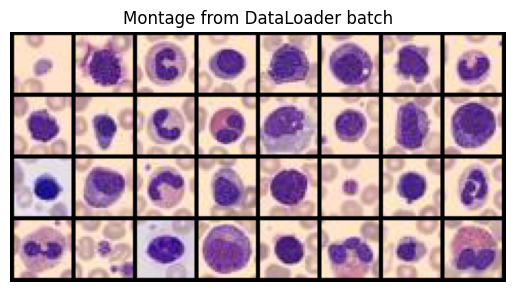

In [8]:
test_loader = DataLoader(dataset=gan_full_dataset,
                         batch_size=32,
                         shuffle=True)
images, _ = next(iter(test_loader))

# Make grid
grid = make_grid((images + 1) / 2, nrow=8)  # Testing GAN dataset rescaling

# Display
plt.imshow(to_pil_image(grid))
plt.axis('off')
plt.title("Montage from DataLoader batch")
plt.show()

In [9]:
# Check image dimension consistency (shapes of individual concatenated datasets)
print("Shapes of the concatenated datasets:")
print(f"Training Set: {vae_full_dataset.datasets[0].imgs.shape}")
print(f"Validaion Set: {vae_full_dataset.datasets[1].imgs.shape}")
print(f"Test Set: {vae_full_dataset.datasets[2].imgs.shape}")

Shapes of the concatenated datasets:
Training Set: (11959, 28, 28, 3)
Validaion Set: (1712, 28, 28, 3)
Test Set: (3421, 28, 28, 3)


0 - basophil: 1218
1 - eosinophil: 3117
2 - erythroblast: 1551
3 - immature granulocytes(myelocytes, metamyelocytes and promyelocytes): 2895
4 - lymphocyte: 1214
5 - monocyte: 1420
6 - neutrophil: 3329
7 - platelet: 2348


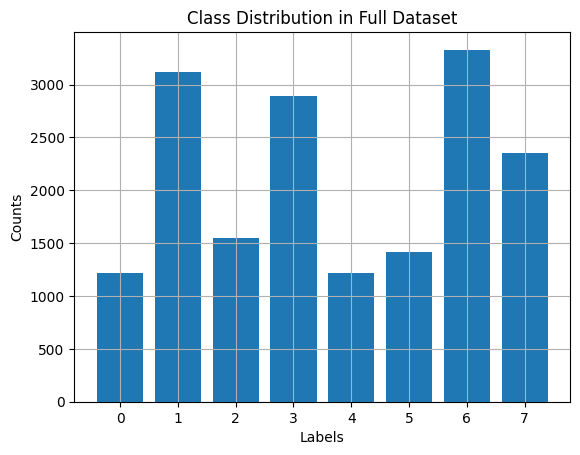

In [10]:
# Class distribution in full dataset
all_labels = np.concatenate([ds.labels for ds in vae_full_dataset.datasets])
num_labels,  counts_combined = np.unique(all_labels, return_counts=True)
for i, count in enumerate(counts_combined):
    print(f"{i} - {labels[str(i)]}: {count}")

# Plotting class distribution
plt.figure()
plt.bar(x=num_labels, height=counts_combined)
plt.grid(True)
plt.xlabel('Labels')
plt.ylabel('Counts')
plt.title('Class Distribution in Full Dataset')
plt.show()

## Data Loading

In [11]:
# Load data into DataLoaders
vae_loader = DataLoader(dataset=vae_full_dataset,
                         batch_size=BATCH_SIZE,
                         shuffle=True)

In [12]:
gan_loader = DataLoader(dataset=gan_full_dataset,
                        batch_size=BATCH_SIZE,
                        shuffle=True)

In [13]:
ddpm_loader = DataLoader(dataset=gan_full_dataset,
                         batch_size=BATCH_SIZE,
                         shuffle=True)

# Autoencoders

In [14]:
def vae_loss(x, x_recon, mu, logvar):
    ''' VAEs use ELBO (see paper), which is split into two parts:
        Reconstruction Loss: How close the reconstructed image is to the
        original input (typically MSE in RGB images with continuous values)
        KL Divergence: Ensures the VAE's sampling follow a standard Gaussian
        distribution (N(0, I)), forming a smooth, continuous, compact latent
        space which produces realistic images (without KL, latent space
        would be sparse, leading to "void" sampling, producing garbage). '''
    # Note: Sum reduction reflects total log-likelihood across all pixels, which
    # lines up with ELBO derivation. An alternative is beta-VAE, where the mean
    # reduction is used and the KLD is tuned using beta: loss = mse + beta * kld
    mse = F.mse_loss(x_recon, x, reduction='sum')
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return mse + kld

In [15]:
def vae_train(model: nn.Module, 
              data_loader: DataLoader, 
              num_epochs=50, device='cpu'):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(),
                                 lr=VAE_LR)
    outputs = []
    
    model.train()
    for epoch in range(num_epochs):
        train_loss = 0
        
        for X, _ in data_loader:
            model.zero_grad()
            X = X.to(device)
            X_recon, mu, logvar = model(X)
            loss = vae_loss(X, X_recon, mu, logvar)
            train_loss += loss
            loss.backward()
            optimizer.step()
            
        train_loss /= len(data_loader)
        print(f'Epoch: {epoch+1}  Loss: {train_loss.detach().item():.4f}')
        
        if epoch % 10 == 0:
            outputs.append((epoch, X.detach().to('cpu'), X_recon.detach().to('cpu')))
            
    model.to('cpu')
    return outputs

## Variational Autoencoder (VAE)

In [16]:
class VAE(nn.Module):
    ''' Creates a VAE for BloodMNIST image generation (customized hidden layers).
        Takes in images shape (C x H x W) and latent space dimension as arguments. '''
    def __init__(self,
                 in_features: tuple[int, int, int],  # C x H x W
                 latent_dim: int):
        super().__init__()
        
        # Encoder
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels=in_features[0], out_channels=32,
                      kernel_size=(3, 3), stride=(2, 2), padding=1),  # (3, 28, 28) -> (32, 14, 14)
            nn.ReLU(),  # (32, 14, 14) -> (32, 14, 14)
            nn.Conv2d(in_channels=32, out_channels=64,
                      kernel_size=(3, 3), stride=(2, 2), padding=1),  # (32, 14, 14) -> (64, 7, 7)
            nn.ReLU(),  # (64, 7, 7) -> (64, 7, 7)
            nn.Conv2d(in_channels=64, out_channels=128,
                      kernel_size=(3, 3), stride=(2, 2)),  # (64, 7, 7) -> (128, 3, 3)
            nn.ReLU(),  # (128, 3, 3) -> (128, 3, 3)
            nn.Flatten()
        )
        
        # Encoder (mean and logvar of latent space for sampling N(mu, var))
        # Note: Logvar is numerically stable and easier to optimize than std or var
        self.mu_layer = nn.Linear(128 * 3 * 3, 
                                  latent_dim)
        self.logvar_layer = nn.Linear(128 * 3 * 3, 
                                      latent_dim)
        
        # Decoder (decode latent space image from sampled latent space "points")
        self.linear_decoder = nn.Linear(latent_dim,
                                        128 * 3 * 3)
        
        # Decoder
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (128, 3, 3)),
            nn.ConvTranspose2d(in_channels=128, out_channels=64,
                               kernel_size=(3, 3), stride=(2, 2)),
            nn.ReLU(),
            nn.ConvTranspose2d(in_channels=64, out_channels=32,
                               kernel_size=(3, 3), stride=(2, 2), padding=1,
                               output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(in_channels=32, out_channels=in_features[0],
                               kernel_size=(3, 3), stride=(2, 2), padding=1,
                               output_padding=1),
            nn.Sigmoid()
        )
        
    def reparametrize(self, mu, logvar):
        ''' Reparametrization technique to make the latent space sampling
            differentiable (direct sampling would break gradient chain). '''
        std = torch.exp(0.5 * logvar)  # Compute standard deviation from logvar
        eps = torch.randn_like(std)  # Input-independent sampling of N(0, 1)
        return mu + eps * std  # The sampling could be written as z = mu + eps * std

    def encode(self, x):
        encoded = self.encoder(x)
        mu = self.mu_layer(encoded)
        logvar = self.logvar_layer(encoded)
        return mu, logvar

    def decode(self, z):
        x = self.linear_decoder(z)
        recon = self.decoder(x)
        return recon

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparametrize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar

In [34]:
vae = VAE(in_features=(3, 28, 28), latent_dim=VAE_ZDIM)
vae_outputs = vae_train(model=vae, 
                        data_loader=vae_loader, 
                        num_epochs=VAE_EPOCHS, 
                        device=device)
torch.save(vae.state_dict(), 'model_VAE.pth')

Epoch: 1  Loss: 20015.5020
Epoch: 2  Loss: 8517.5947
Epoch: 3  Loss: 6804.7705
Epoch: 4  Loss: 6024.7383
Epoch: 5  Loss: 5584.1821
Epoch: 6  Loss: 5289.8110
Epoch: 7  Loss: 5069.7124
Epoch: 8  Loss: 4879.0229
Epoch: 9  Loss: 4729.3037
Epoch: 10  Loss: 4598.6035
Epoch: 11  Loss: 4501.2852
Epoch: 12  Loss: 4418.2783
Epoch: 13  Loss: 4356.4561
Epoch: 14  Loss: 4310.6201
Epoch: 15  Loss: 4276.3926
Epoch: 16  Loss: 4231.6143
Epoch: 17  Loss: 4202.1538
Epoch: 18  Loss: 4181.3364
Epoch: 19  Loss: 4149.4414
Epoch: 20  Loss: 4125.0601
Epoch: 21  Loss: 4099.5854
Epoch: 22  Loss: 4081.0396
Epoch: 23  Loss: 4057.7300
Epoch: 24  Loss: 4048.0737
Epoch: 25  Loss: 4032.6951
Epoch: 26  Loss: 4014.3718
Epoch: 27  Loss: 4003.6753
Epoch: 28  Loss: 3991.8284
Epoch: 29  Loss: 3987.7314
Epoch: 30  Loss: 3971.7439
Epoch: 31  Loss: 3965.9360
Epoch: 32  Loss: 3955.9636
Epoch: 33  Loss: 3954.3914
Epoch: 34  Loss: 3951.1848
Epoch: 35  Loss: 3940.7761
Epoch: 36  Loss: 3932.5732
Epoch: 37  Loss: 3927.5942
Epoch: 38

## Visualizing Results

In [17]:
def plot_results(outputs: list[tuple[int, torch.Tensor, torch.Tensor]], 
                 color_channels=3, width=28, height=28, rescale=False):
    for i in range(len(outputs)):
        plt.figure(figsize=(9, 2))
        imgs = outputs[i][1].detach().numpy()
        recon = outputs[i][2].detach().numpy()
        if rescale:  # [-1, 1] -> [0, 1]
            imgs = (imgs + 1) / 2
            recon = (recon + 1) / 2
        
        for i, item in enumerate(imgs):
            if i >= 9: break
            plt.subplot(2, 9, i+1)
            plt.axis('off')
            item = item.reshape(color_channels, height, width)
            plt.imshow(np.transpose(item, (1, 2, 0)))
    
        for i, item in enumerate(recon):
            if i >= 9: break
            plt.subplot(2, 9, 9+i+1)
            plt.axis('off')
            item = item.reshape(color_channels, height, width)
            plt.imshow(np.transpose(item, (1, 2, 0)))

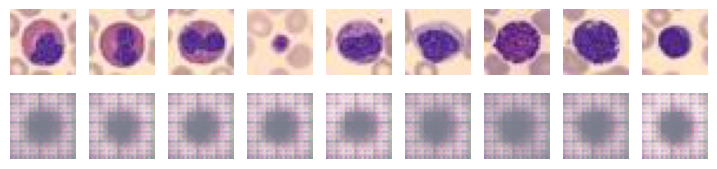

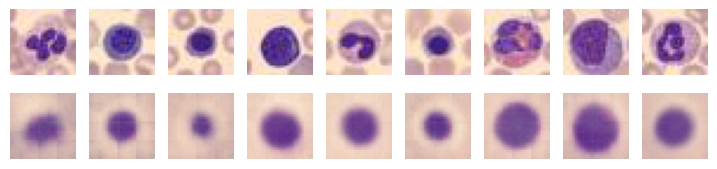

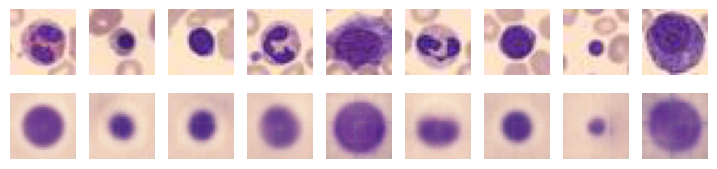

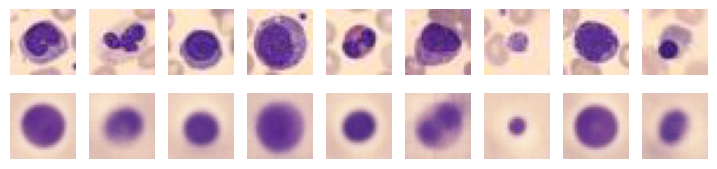

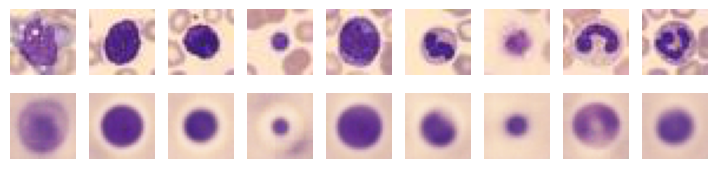

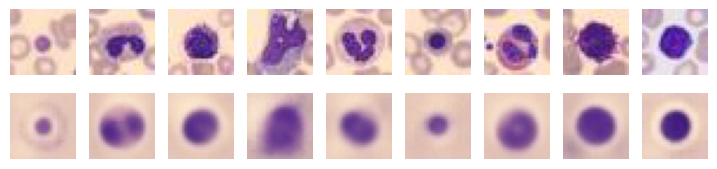

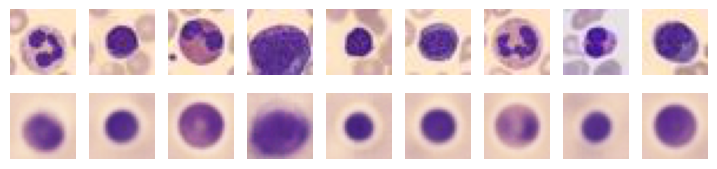

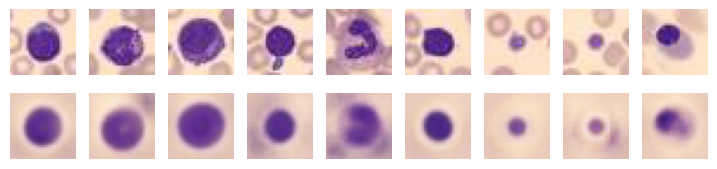

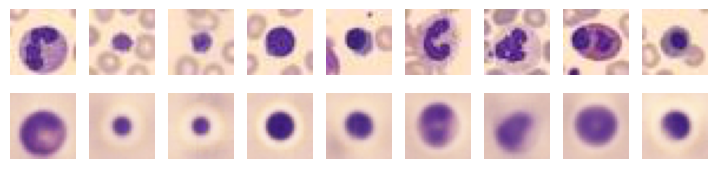

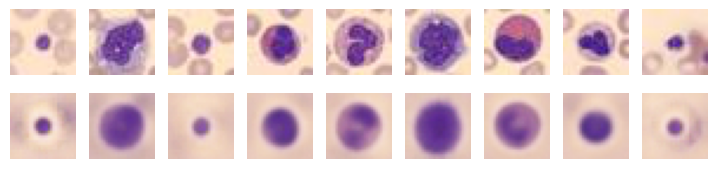

In [36]:
plot_results(vae_outputs, color_channels=3, width=28, height=28)

# Generative Adversarial Networks (GANs)

In [17]:
# Instead of BCE, LSGAN implements Least Squares loss to deal the mode collapse and
# vanishing gradients. Most implementations use mean instead of sum of squared errors
# to keep the scale of the loss stable.

def discriminator_loss(real_output: torch.Tensor, fake_output: torch.Tensor):
    ''' Computes the Least Squares loss for the discriminator.
        Takes in the discriminator's output for real images (real_output) and
        for fake images (fake_output). '''
    # D(x) should be close to 1 for real images
    real_loss = F.mse_loss(real_output, torch.ones_like(real_output))
    
    # D(x) should be close to 0 for fake images
    fake_loss = F.mse_loss(fake_output, torch.zeros_like(fake_output))
    
    return 0.5*real_loss + 0.5*fake_loss

def generator_loss(fake_output: torch.Tensor):
    ''' Computes the Least Squares loss for the generator. 
        Takes in the discriminator's output for fake images (fake_output). '''
    # D(x) should be close to 1 for fake images
    return 0.5*F.mse_loss(fake_output, torch.ones_like(fake_output))

In [18]:
def gan_train(netD: nn.Module, 
              netG: nn.Module,
              data_loader: DataLoader, 
              num_epochs=50, device='cpu'):
    netD.to(device), netG.to(device)
    #real_label = 1
    #fake_label = 0
    optimizerD = optim.Adam(netD.parameters(), lr=GAN_LR, betas=(GAN_BETA1, 0.999))
    optimizerG = optim.Adam(netG.parameters(), lr=GAN_LR, betas=(GAN_BETA1, 0.999))
    outputs = []
    
    print('D(x) -> 1, D(G(z)) -> 0/1')
    netD.train(), netG.train()
    for epoch in range(num_epochs):
        train_lossD = 0
        train_lossG = 0
        train_Dx = 0  # Average discriminator guess on real data (Dx -> 1)
        train_DGz1 = 0  # Average discriminator guess on fake data (D(G(z)) -> 0)
        train_DGz2 = 0  # Average discriminator guess on fake data after DGz1 (D(G(z)) -> 1)
        
        for real_X, _ in data_loader:
            real_X.to(device)
            
            # Step 1: Get discriminator's outputs on real batch
            netD.zero_grad()
            real_output = netD(real_X).squeeze()
            
            # Step 2: Get discriminator's output on fake batch
            noise = torch.randn(BATCH_SIZE, GAN_ZDIM, 1, 1,
                                device=device)
            fake_X = netG(noise)
            fake_output1 = netD(fake_X.detach()).squeeze()  # Detach generator's graph
            
            # Step 3: Compute discriminator loss and backpropagate
            loss_D = discriminator_loss(real_output, fake_output1)
            loss_D.backward()
            optimizerD.step()
            
            # Step 4: Get discriminator's output on fake batch and train generator
            netG.zero_grad()
            fake_output2 = netD(fake_X).squeeze()  # Don't detach generator's graph
            loss_G = generator_loss(fake_output2)
            loss_G.backward()
            optimizerG.step()
            
            train_lossD += loss_D.detach().item()
            train_lossG += loss_G.detach().item()
            train_Dx += real_output.detach().mean().item()
            train_DGz1 += fake_output1.detach().mean().item()
            train_DGz2 += fake_output2.detach().mean().item()
            
        if epoch % 10 == 0:
            outputs.append((epoch, real_X.detach().to('cpu'), fake_X.detach().to('cpu')))
            
        train_lossD /= len(data_loader)
        train_lossG /= len(data_loader)
        train_Dx /= len(data_loader)
        train_DGz1 /= len(data_loader)
        train_DGz2 /= len(data_loader)
        print(f'Epoch: {epoch+1}  '
              f'Loss_D: {train_lossD:.4f}  Loss_G: {train_lossG:.4f}  '
              f'D(x): {train_Dx:.4f}  D(G(z)): {train_DGz1:.4f}/{train_DGz2:.4f}')
        
    netD.to('cpu'), netG.to('cpu')
    return outputs

## DCGAN + LSGAN

*Note:* The generator/discriminator follow a similar architecture to the encoder/decoder in the VAE, with some modifications to align with guidelines in the DCGANs paper (https://arxiv.org/pdf/1511.06434)

In [19]:
class Generator(nn.Module):
    ''' Creates a generator for the DCGAN of the BloodMNIST dataset. 
        Takes in the number of dimensions of the input noise vector and
        the number of output color channels (fake image color channels). '''
    def __init__(self, z_dim: int, out_channels: int):
        # Note: DCGAN paper uses 100 dims for z. For our case, 16 might suffice (lower res, less details to encode).
        super().__init__()
        
        self.layer_stack = nn.Sequential(
            nn.ConvTranspose2d(in_channels=z_dim, out_channels=128,
                               kernel_size=(3, 3), stride=(2, 2)),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            
            nn.ConvTranspose2d(in_channels=128, out_channels=64,
                               kernel_size=(3, 3), stride=(2, 2)),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            
            nn.ConvTranspose2d(in_channels=64, out_channels=32,
                               kernel_size=(3, 3), stride=(2, 2), padding=1,
                               output_padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            
            nn.ConvTranspose2d(in_channels=32, out_channels=out_channels,
                               kernel_size=(3, 3), stride=(2, 2), padding=1,
                               output_padding=1),
            nn.Tanh()  # This requires input to be scaled to [-1, 1]
        )
        
    def forward(self, z):
        # Assumes z shape is (batch_size, z_dim)
        z = z.view(z.size(0), z.size(1), 1, 1)  # (B, z_dim, 1, 1)
        return self.layer_stack(z)

In [20]:
class Discriminator(nn.Module):
    ''' Creates a discriminator for the DCGAN of the BloodMNIST dataset. 
        Takes in the number of input color channels (real/fake images). '''
    def __init__(self, in_channels: int):
        super().__init__()
        
        self.layer_stack = nn.Sequential(
            # Note: The paper uses 3 -> 128 color channels. That's overkill and worse for our case.
            nn.Conv2d(in_channels=in_channels, out_channels=32,
                      kernel_size=(3, 3), stride=(2, 2), padding=1),  # (3, 28, 28) -> (16, 14, 14)
            nn.LeakyReLU(0.2),  # (16, 14, 14) -> (16, 14, 14)
            
            nn.Conv2d(in_channels=32, out_channels=64,
                      kernel_size=(3, 3), stride=(2, 2), padding=1),  # (16, 14, 14) -> (32, 7, 7)
            nn.BatchNorm2d(64),
            nn.LeakyReLU(0.2),  # (32, 7, 7) -> (32, 7, 7)
            
            nn.Conv2d(in_channels=64, out_channels=128,
                      kernel_size=(3, 3), stride=(2, 2)),  # (32, 7, 7) -> (64, 3, 3)
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2),  # (64, 3, 3) -> (64, 3, 3)
            
            nn.Conv2d(in_channels=128, out_channels=1,
                      kernel_size=(3, 3), stride=(2, 2))  # (64, 3, 3) -> (1, 1, 1)
            #nn.Sigmoid()  # LSGAN requires unbounded, logit output to compute MSE
        )
        
    def forward(self, x):
        y = self.layer_stack(x)
        return y.view(-1, 1)

In [ ]:
netD = Discriminator(in_channels=3)
netG = Generator(z_dim=GAN_ZDIM, out_channels=3)
gan_outputs = gan_train(netD=netD, netG=netG,
                        data_loader=gan_loader,
                        num_epochs=GAN_EPOCHS,
                        device=device)
torch.save(netD.state_dict(), 'model_netD.pth')
torch.save(netG.state_dict(), 'model_netG.pth')

D(x) -> 1, D(G(z)) -> 0/1


Epoch: 1  Loss_D: 0.0750  Loss_G: 0.5615  D(x): 0.9296  D(G(z)): 0.1295/-0.0379
Epoch: 2  Loss_D: 0.0678  Loss_G: 0.5529  D(x): 0.8930  D(G(z)): 0.1080/-0.0234
Epoch: 3  Loss_D: 0.1213  Loss_G: 0.4072  D(x): 0.7581  D(G(z)): 0.2356/0.1335
Epoch: 4  Loss_D: 0.1379  Loss_G: 0.3358  D(x): 0.7060  D(G(z)): 0.2951/0.2096
Epoch: 5  Loss_D: 0.1398  Loss_G: 0.3417  D(x): 0.7034  D(G(z)): 0.3000/0.2034
Epoch: 6  Loss_D: 0.1394  Loss_G: 0.3642  D(x): 0.7133  D(G(z)): 0.2910/0.1910
Epoch: 7  Loss_D: 0.1393  Loss_G: 0.3596  D(x): 0.7104  D(G(z)): 0.2878/0.2015
Epoch: 8  Loss_D: 0.1341  Loss_G: 0.3473  D(x): 0.7125  D(G(z)): 0.2899/0.2087
Epoch: 9  Loss_D: 0.1272  Loss_G: 0.3556  D(x): 0.7256  D(G(z)): 0.2736/0.1971
Epoch: 10  Loss_D: 0.1344  Loss_G: 0.3901  D(x): 0.7359  D(G(z)): 0.2677/0.1743
Epoch: 11  Loss_D: 0.1140  Loss_G: 0.3390  D(x): 0.7440  D(G(z)): 0.2563/0.2076
Epoch: 12  Loss_D: 0.1110  Loss_G: 0.4412  D(x): 0.7679  D(G(z)): 0.2383/0.1185
Epoch: 13  Loss_D: 0.1137  Loss_G: 0.3452  D(x)

## Visualizing Results

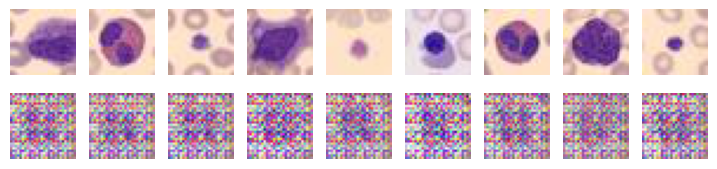

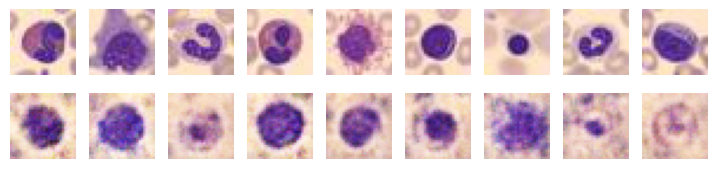

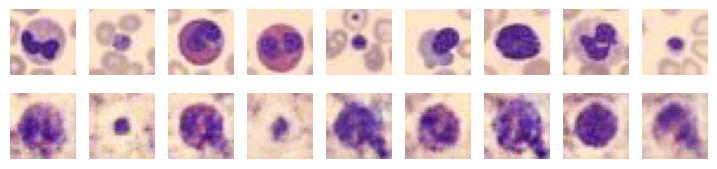

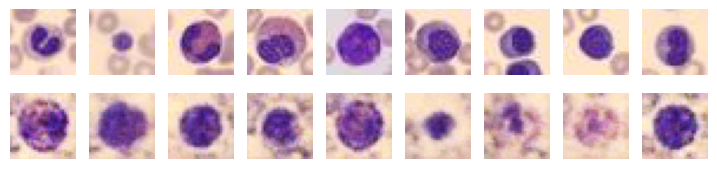

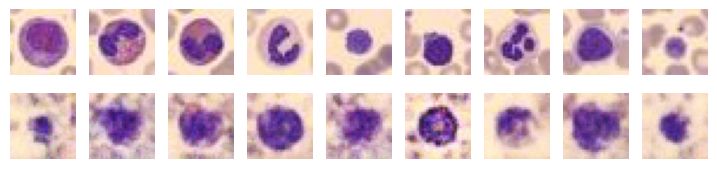

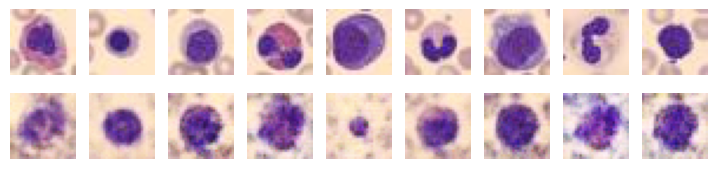

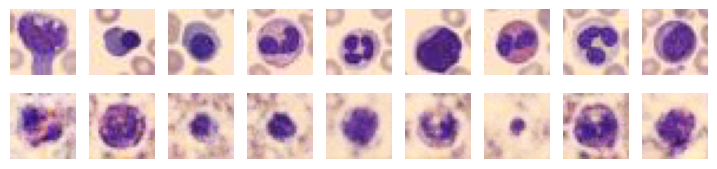

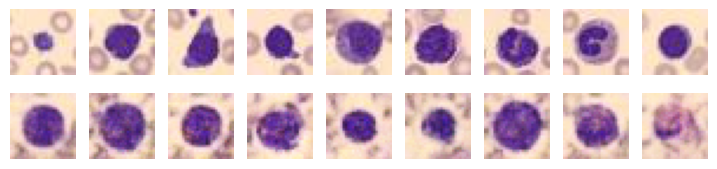

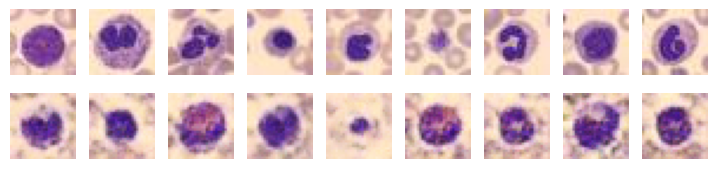

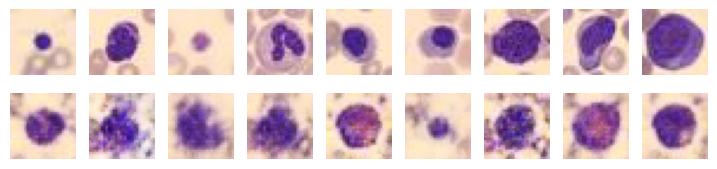

In [ ]:
plot_results(gan_outputs, color_channels=3, width=28, height=28, rescale=True)

# Diffusion Models

In [21]:
# Sinusoidal embeddings help models better understand time dependencies through 
# high-dimensional encodings of timesteps.
def sinusoidal_embeddings(t, d):
    ''' Computes the sinusoidal position embeddings at timestep t.
        Receives the timestep (t) and the dimensions of each vector 
        embedding (d) as arguments. '''
    embeddings = torch.zeros((t, d))  # Each timestep has a vector embedding of dim d
    pos = torch.arange(0, t).unsqueeze(dim=1)  # Represents each timestep (pos)
    denom = torch.pow(10000, 2*torch.arange(0, d//2)/d)  # 10000**(2i/d_model), i is the vector index
    
    embeddings[:, 0::2] = torch.sin(pos/denom)  # Even vector indices are computed with sin
    embeddings[:, 1::2] = torch.cos(pos/denom)  # Odd vector indices are computed with cos
    return embeddings

In [22]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int,
                 kernel_size=3, stride=1, padding=1, dropout=0.1, 
                 norm1=True, norm2=True):
        super().__init__()
        
        self.norm1 = nn.GroupNorm(in_channels//4, in_channels) if norm1 else nn.Identity()
        self.activation = nn.SiLU()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding)

        self.norm2 = nn.GroupNorm(out_channels//4, out_channels) if norm2 else nn.Identity()
        self.dropout = nn.Dropout(p=dropout)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size, stride, padding)

        self.skip = (nn.Identity() if in_channels == out_channels else
                     nn.Conv2d(in_channels, out_channels, 
                               kernel_size=1, stride=1, padding=0))  # Skip connection
        
    def forward(self, x, temb):
        residual = self.skip(x)
        
        h = self.activation(self.norm1(x))
        h = self.conv1(h)
        h += temb[:, :, None, None]
        h = self.activation(self.norm2(h))
        h = self.dropout(h)
        h = self.conv2(h)
        
        return h + residual
    
class ResidualBlockGroup(nn.Module):
    def __init__(self, blocks):
        super().__init__()
        self.blocks = nn.ModuleList(blocks)

    def forward(self, x, temb):
        for block in self.blocks:
            x = block(x, temb)
        return x

In [23]:
class UNet(nn.Module):
    def __init__(self, n_steps=1000, start_ch=32):
        super().__init__()
        self.n_steps = n_steps
        self.start_ch = start_ch
        
        # Sinusoidal embedding
        self.time_embed = nn.Embedding(n_steps, start_ch)
        self.time_embed.weight.data = sinusoidal_embeddings(n_steps, start_ch)
        self.time_embed.requires_grad_(False)
        
        # Transformation of embedding
        self.transform_emb = nn.Sequential(
            nn.Linear(start_ch, start_ch*4),
            nn.SiLU(),
            nn.Linear(start_ch*4, start_ch*4)
        )
        
        # Downsampling (B, 3, 28, 28)
        self.conv0 = nn.Conv2d(3, start_ch, kernel_size=3, stride=1, padding=1)
        
        # (B, C, 28, 28)
        self.te_db1 = self.make_te(start_ch*4, start_ch)
        self.db1 = ResidualBlockGroup([
            ResidualBlock(start_ch, start_ch),
            ResidualBlock(start_ch, start_ch)
        ])
        self.d1 = nn.Conv2d(start_ch, start_ch*2, kernel_size=3, stride=2, padding=1)
        
        # (B, C*2, 14, 14)
        self.te_db2 = self.make_te(start_ch*4, start_ch*2)
        self.db2 = ResidualBlockGroup([
            ResidualBlock(start_ch*2, start_ch*2),
            ResidualBlock(start_ch*2, start_ch*2)
        ])
        self.d2 = nn.Conv2d(start_ch*2, start_ch*4, kernel_size=3, stride=2, padding=1)
        
        # (B, C*4, 7, 7)
        self.te_db3 = self.make_te(start_ch*4, start_ch*4)
        self.db3 = ResidualBlockGroup([
            ResidualBlock(start_ch*4, start_ch*4),
            ResidualBlock(start_ch*4, start_ch*4)
        ])
        self.d3 = nn.Conv2d(start_ch*4, start_ch*4, kernel_size=3, stride=2, padding=1)
        
        # Bottleneck (B, C*4, 4, 4)
        self.te_bottleneck = self.make_te(start_ch*4, start_ch*4)
        self.bottleneck = ResidualBlockGroup([
            ResidualBlock(start_ch*4, start_ch*4),
            ResidualBlock(start_ch*4, start_ch*4)
        ])
        
        # Upsampling (B, C*4, 4, 4)
        self.u1 = nn.ConvTranspose2d(start_ch*4, start_ch*4, kernel_size=3, stride=2, 
                                     padding=1)
        self.te_ub1 = self.make_te(start_ch*4, start_ch*4)
        self.ub1 = ResidualBlockGroup([
            ResidualBlock(start_ch*4*2, start_ch*4),
            ResidualBlock(start_ch*4, start_ch*4)
        ])
        
        # (B, C*4, 7, 7)
        self.u2 = nn.ConvTranspose2d(start_ch*4, start_ch*2, kernel_size=3, stride=2,
                                     padding=1, output_padding=1)
        self.te_ub2 = self.make_te(start_ch*4, start_ch*2)
        self.ub2 = ResidualBlockGroup([
            ResidualBlock(start_ch*2*2, start_ch*2),
            ResidualBlock(start_ch*2, start_ch*2)
        ])
        
        # (B, C*2, 14, 14)
        self.u3 = nn.ConvTranspose2d(start_ch*2, start_ch, kernel_size=3, stride=2,
                                     padding=1, output_padding=1)
        self.te_ub3 = self.make_te(start_ch*4, start_ch)
        self.ub3 = ResidualBlockGroup([
            ResidualBlock(start_ch*2, start_ch),
            ResidualBlock(start_ch, start_ch)
        ])
        
        # (B, C, 28, 28)
        self.conv_t0 = nn.Sequential(
            nn.GroupNorm(start_ch//4, start_ch),
            nn.SiLU(),
            nn.ConvTranspose2d(start_ch, 3, kernel_size=3, stride=1, padding=1)
        )
        
    def make_te(self, dim_in: int, out_channels: int):
        emb_mlp = nn.Sequential(
            nn.SiLU(),
            nn.Linear(dim_in, out_channels)
        )
        return emb_mlp
        
    def forward(self, x, t):
        # Transform timestep embedding and initial image convolution
        temb = self.transform_emb(self.time_embed(t))  # (128, 128)
        out0 = self.conv0(x)  # (128, 32, 28, 28)
        
        # Downsampling
        out1 = self.db1(out0, self.te_db1(temb))  # (128, 32, 28, 28)
        out2 = self.db2(self.d1(out1), self.te_db2(temb))  # (128, 64, 14, 14)
        out3 = self.db3(self.d2(out2), self.te_db3(temb))  # (128, 128, 7, 7)
        
        # Bottleneck
        out4 = self.bottleneck(self.d3(out3), self.te_bottleneck(temb))  # (128, 128, 4, 4)
        
        # Upsampling
        out5 = torch.concat([self.u1(out4), out3], dim=1)  # (128, 256, 7, 7)
        out5 = self.ub1(out5, self.te_ub1(temb))  # (128, 128, 7, 7)
        out6 = torch.concat([self.u2(out5), out2], dim=1)  # (128, 128, 14, 14)
        out6 = self.ub2(out6, self.te_ub2(temb))  # (128, 64, 14, 14)
        out7 = torch.concat([self.u3(out6), out1], dim=1)  # (128, 64, 14, 14)
        out7 = self.ub3(out7, self.te_ub3(temb))  # (128, 32, 28, 28)
        
        # Final transform to image
        out_final = self.conv_t0(out7)  # (128, 3, 28, 28)
        
        return out_final

## DDPM

In [24]:
class DDPM(nn.Module):
    def __init__(self, model: UNet, n_steps=1000, beta1=1e-4, betaT=0.02):
        super().__init__()
        
        self.model = model
        self.n_steps = n_steps
        assert model.n_steps == self.n_steps
        
        # Betas increase linearly from 1e-4 (beta1) to 0.02 (betaT)
        self.betas = torch.linspace(beta1, betaT, n_steps)
        self.alphas = 1.0 - self.betas
        self.alphas_bar = torch.cumprod(self.alphas, dim=0)
    
    def forward(self, x0: torch.Tensor, t: torch.Tensor, noise=None):
        ''' Computes the forward (diffusion) process at t.
            Takes in an the original image (x0), a tensor of time steps (t) 
            and a noise tensor (noise, epsilon in the equation). '''
        # Retrieve necessary parameters at time step t
        alpha_bar_t = self.alphas_bar[t].reshape(-1, 1, 1, 1)
        if noise is None:
            noise = torch.randn_like(x0)
        
        # Compute noisy image at time step t
        # Note: The following is a reparameterization of Eq.(4) in the paper
        xt = torch.sqrt(alpha_bar_t) * x0 + torch.sqrt(1.0-alpha_bar_t) * noise
        
        return xt
    
    def backward(self, x: torch.Tensor, t: torch.Tensor):
        ''' Computes the backward process using the given model. 
            Takes in a batch of images (x) and a vector of timesteps (t). '''
        return self.model(x, t)

In [25]:
def ddpm_train(ddpm: DDPM, 
               data_loader: DataLoader, 
               num_epochs=50, device='cpu'):
    ddpm.to(device)
    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(ddpm.parameters(),
                                 lr=VAE_LR)
    outputs = []
    
    ddpm.train()
    for epoch in tqdm(range(num_epochs), desc=f"Training progress", colour="#00ff00"):
        train_loss = 0
        
        for x0, _ in tqdm(data_loader, leave=False, desc=f"Epoch {epoch + 1}/{num_epochs}", colour="#005500"):
            ddpm.zero_grad()
            x0 = x0.to(device)
            
            # Generate noise mask and random time steps
            noise = torch.randn_like(x0).to(device)  # Random Gaussian noise
            t = torch.randint(0, DDPM_STEPS, (len(x0),))
            
            # Forward (diffusion) process
            noisy_x0 = ddpm.forward(x0, t, noise)
            
            # Backward process - estimate noise added to image
            noise_est = ddpm.backward(noisy_x0, t)
            
            # Compute loss between estimate and actual noise and optimize
            loss = criterion(noise, noise_est)
            loss.backward()
            optimizer.step()

            train_loss += loss

        train_loss /= len(data_loader)
        print(f'Epoch: {epoch+1}  Loss: {train_loss.detach().item():.4f}')
        
        if epoch % 5 == 0:
            outputs.append((epoch, x0.detach().to('cpu'), noise_est.detach().to('cpu')))
            
    ddpm.to('cpu')
    return outputs

In [46]:
ddpm = DDPM(model=UNet(n_steps=DDPM_STEPS, start_ch=16),
            n_steps=DDPM_STEPS, beta1=DDPM_BETA1, betaT=DDPM_BETAT)
ddpm_outputs = ddpm_train(ddpm=ddpm,
                          data_loader=ddpm_loader,
                          num_epochs=DDPM_EPOCHS,
                          device=device)
torch.save(ddpm.state_dict(), 'model_DDPM.pth')

Training progress:   0%|          | 0/50 [00:00<?, ?it/s]

Training progress:   2%|▏         | 1/50 [00:35<29:05, 35.62s/it]

Epoch: 1  Loss: 0.8002


Training progress:   4%|▍         | 2/50 [01:10<28:06, 35.14s/it]

Epoch: 2  Loss: 0.3789


Training progress:   6%|▌         | 3/50 [01:45<27:31, 35.14s/it]

... (91 outputs left out)

Training progress:  98%|█████████▊| 49/50 [28:48<00:35, 35.21s/it]

Epoch: 49  Loss: 0.0331


Training progress: 100%|██████████| 50/50 [29:24<00:00, 35.28s/it]

Epoch: 50  Loss: 0.0329


## DDIM Sampling

In [26]:
def ddim_sample(ddpm: DDPM, n_samples=16, n_steps=50, eta=0.0, device='cpu'):
    ''' Performs DDIM sampling over the trained DDPM model.
        Receives a trained DDPM (ddpm), the number of samples to generate, 
        the number of steps for sampling (n_steps) and a measure of noise 
        to be introduced in each time step (eta). '''
    B, C, H, W = (n_samples, 3, 28, 28)
    ddpm.model.to(device)
    
    # Generate a reduced timestep schedule (50 linearly separated in [0, 1000])
    ddim_time = torch.linspace(0, ddpm.n_steps-1, n_steps, dtype=torch.int16)
    
    with torch.inference_mode():
        # Full Gaussian noise
        x = torch.randn((B, C, H, W)).to(device)
        
        alphas_bar = ddpm.alphas_bar
        sqrt_ab = torch.sqrt(alphas_bar)
        sqrt_one_minus_ab = torch.sqrt(1-alphas_bar)
        
        for i in reversed(range(n_steps)):
            t = ddim_time[i].item()
            time_tensor = (torch.ones((B,)) * t).to(device).long()
            noise_est = ddpm.backward(x, time_tensor)
            
            # Estimate x0 (derived from Eq.(4) in DDIM paper)
            x0 = (x - sqrt_one_minus_ab[t] * noise_est) / sqrt_ab[t]
            x0 = x0.clamp(-1, 1)
            
            if i > 0:
                t_prev = ddim_time[i-1].item()
                alpha_bar_t = alphas_bar[t]
                alpha_bar_prev = alphas_bar[t_prev]
                
                sigma_t = torch.sqrt(
                    (1 - alpha_bar_prev) / (1 - alpha_bar_t) * (1 - alpha_bar_t / alpha_bar_prev)
                )
                noise = torch.randn_like(x) if eta > 0 else 0.0  # Random noise
                
                x = (
                    torch.sqrt(alpha_bar_prev) * x0 +  # sqrt(alpha_bar_prev) * "predicted x0"
                    torch.sqrt(1 - alpha_bar_prev - sigma_t ** 2) * noise_est +  # Direction pointing to xt
                    sigma_t * noise
                )
            else:
                x = x0
    
    return x

## Visualizing Results

In [27]:
def generate_images(ddpm: DDPM, n_samples=16, beta_option=1, gif_name=None, 
                    frames_per_gif=100, device='cpu'):
    ''' Generates images and GIF with DDPM sampling'''
    frame_idxs = np.linspace(0, ddpm.n_steps, frames_per_gif, dtype=np.uint16)
    frames = []  # Each frame in the GIF is a timestep
    
    with torch.inference_mode():
        # Full Gaussian noise
        x = torch.randn((n_samples, 3, 28, 28)).to(device)
        
        # Revert Gaussian noise step by step
        for idx, t in enumerate(reversed(list(range(ddpm.n_steps)))):
            time_tensor = (torch.ones((n_samples,)) * t).long().to(device)
            noise_est = ddpm.backward(x, time_tensor)
            
            alpha_t = ddpm.alphas[t]
            alpha_bar_t = ddpm.alphas_bar[t]
            
            # Estimate x0 (denoise)
            x = (1 / alpha_t.sqrt()) * (x - (1 - alpha_t) / (1 - alpha_bar_t).sqrt() * noise_est)
            
            if t > 0:
                z = torch.randn(n_samples, 3, 28, 28).to(device)
                
                sigma_t = None
                beta_t = ddpm.betas[t]
                if beta_option == 2:  # Variance_t = beta_tilda_t
                    prev_alpha_bar_t = ddpm.alphas_bar[t-1] if t > 0 else ddpm.alphas[0]
                    beta_tilda_t = ((1 - prev_alpha_bar_t)/(1 - alpha_bar_t)) * beta_t
                    sigma_t = beta_tilda_t.sqrt()
                else:
                    sigma_t = beta_t.sqrt()
                    
                # Add stochastic noise (Langevin Dynamics) to explore the space
                x = x + sigma_t * z
            
            if frame_idxs is None or t in frame_idxs or t == 0:
                # Clone to avoid in-place ops
                normalized = ((x + 1) / 2).clamp(0, 1) * 255  # [B, C, H, W]
                normalized = normalized.cpu().to(torch.uint8)

                # Handle non-square batch sizes
                b1 = int(n_samples ** 0.5)
                b2 = (n_samples + b1 - 1) // b1  # ceiling division

                # If batch size is smaller than expected, pad with zeros
                if normalized.shape[0] < b1 * b2:
                    pad = torch.zeros((b1 * b2 - normalized.shape[0], *normalized.shape[1:]), dtype=normalized.dtype)
                    normalized = torch.cat([normalized, pad], dim=0)

                # Rearrange to square frame
                frame = einops.rearrange(normalized, "(b1 b2) c h w -> (b1 h) (b2 w) c", b1=b1, b2=b2)

                # If grayscale, repeat to RGB
                if frame.shape[2] == 1:
                    frame = frame.repeat(1, 1, 3)

                frames.append(frame.numpy())

    # Save the gif
    if gif_name:
        with imageio.get_writer(gif_name, mode="I") as writer:
            for idx, frame in enumerate(frames):
                writer.append_data(frame)

                # Extend final frame
                if idx == len(frames) - 1:
                    for _ in range(frames_per_gif // 3):
                        writer.append_data(frame)
    return x


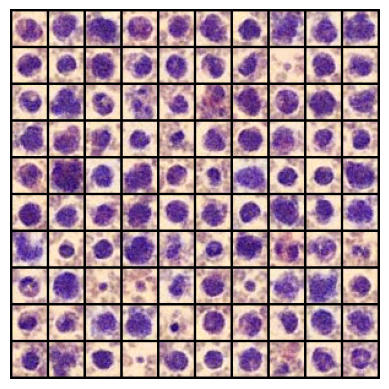

In [53]:
# Generate new images (DDPM sampling)
imgs = generate_images(ddpm, n_samples=100, gif_name='DDPM.gif', device=device)
imgs_norm = ((imgs + 1) / 2).clamp(0, 1)
grid = make_grid(imgs_norm, nrow=10)
plt.imshow(to_pil_image(grid))
plt.axis('off')
plt.show()

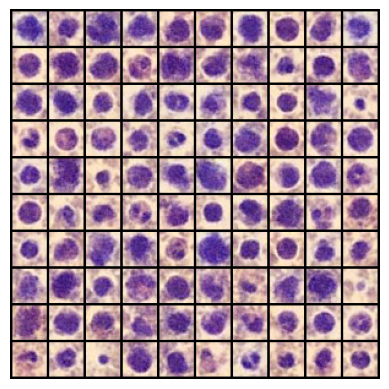

In [ ]:
# Generate new images (DDIM sampling)
imgs = ddim_sample(ddpm, n_steps=25, n_samples=100, eta=0.1)
imgs_norm = ((imgs + 1) / 2).clamp(0, 1)
grid = make_grid(imgs_norm, nrow=10)
plt.imshow(to_pil_image(grid))
plt.axis('off')
plt.show()

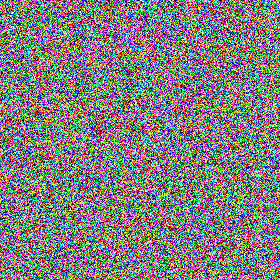

In [55]:
# Visualize generated GIF
Image(open('DDPM.gif', 'rb').read())

# Model Evaluation

## Randomly Generate Images

In [29]:
def vae_generate_images(vae: VAE, latent_dim=16, n_samples=10000, batch_size=100, 
                        device='cpu', save_path='VAE_10000.npz'):
    vae.to(device)
    vae.eval()

    generated = []

    with torch.no_grad():
        for i in range(0, n_samples, batch_size):
            current_batch_size = min(batch_size, n_samples - i)
            # Sample latent vectors from standard normal prior
            z = torch.randn(current_batch_size, latent_dim).to(device)

            # Decode latent vectors
            imgs = vae.decode(z)  # shape: (batch_size, C, H, W), values in [0,1]

            # Convert to CPU numpy arrays, scale to [0,255] uint8 if you want
            imgs = imgs.cpu().numpy()
            imgs = (imgs * 255).astype(np.uint8)

            generated.append(imgs)

    # Concatenate all images (shape: (n_samples, C, H, W))
    generated = np.concatenate(generated, axis=0)

    # Save as .npz file (or use np.save if you prefer)
    np.savez_compressed(save_path, images=generated)

    print(f"Saved {n_samples} images to {save_path}")

In [30]:
vae = VAE(in_features=(3, 28, 28), latent_dim=VAE_ZDIM)
vae.load_state_dict(torch.load('model_VAE.pth'))

<All keys matched successfully>

In [31]:
for i in range(5):
    if not os.path.isfile(f'VAE_10000_{i+1}.npz'):
        vae_generate_images(vae, latent_dim=VAE_ZDIM, save_path=f'VAE_10000_{i+1}.npz')

(10000, 3, 28, 28)


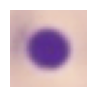

In [32]:
data = np.load('VAE_10000_1.npz')
images = data['images']
print(images.shape)
plt.figure(figsize=(1, 1))
plt.axis('off')
plt.imshow(np.transpose(images[0], (1, 2, 0)))
plt.show()

In [33]:
def gan_generate_images(netG: Generator, latent_dim=16, n_samples=10000, batch_size=100, 
                        device='cpu', save_path='GAN_10000.npz'):
    netG.to(device)
    netG.eval()

    generated = []

    with torch.no_grad():
        for i in range(0, n_samples, batch_size):
            current_batch_size = min(batch_size, n_samples - i)
            # Sample latent vectors from standard normal prior
            z = torch.randn(current_batch_size, latent_dim).to(device)

            # Decode latent vectors
            imgs = netG(z)  # shape: (batch_size, C, H, W), values in [0,1]
            imgs = (imgs + 1) / 2

            # Convert to CPU numpy arrays, scale to [0,255] uint8 if you want
            imgs = imgs.cpu().numpy()
            imgs = (imgs * 255).astype(np.uint8)

            generated.append(imgs)

    # Concatenate all images (shape: (n_samples, C, H, W))
    generated = np.concatenate(generated, axis=0)

    # Save as .npz file (or use np.save if you prefer)
    np.savez_compressed(save_path, images=generated)

    print(f"Saved {n_samples} images to {save_path}")

In [29]:
netG = Generator(z_dim=GAN_ZDIM, out_channels=3)
netG.load_state_dict(torch.load('model_netG.pth'))

<All keys matched successfully>

In [35]:
for i in range(5):
    if not os.path.isfile(f'GAN_10000_{i+1}.npz'):
        gan_generate_images(netG, latent_dim=GAN_ZDIM, save_path=f'GAN_10000_{i+1}.npz')

(10000, 3, 28, 28)


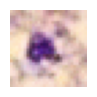

In [36]:
data = np.load('GAN_10000_1.npz')
images = data['images']
print(images.shape)
plt.figure(figsize=(1, 1))
plt.axis('off')
plt.imshow(np.transpose(images[1], (1, 2, 0)))
plt.show()

In [37]:
def ddim_generate_images(ddpm: DDPM, n_steps=25, eta=0.1, n_samples=10000, batch_size=100, 
                         device='cpu', save_path='DDIM_10000.npz'):
    ddpm.model.to(device)
    ddpm.model.eval()

    generated = []

    with torch.no_grad():
        for i in range(0, n_samples, batch_size):
            # Sample from DDIM
            imgs = ddim_sample(ddpm, n_samples=batch_size, n_steps=n_steps, eta=eta)
            imgs = (imgs + 1) / 2

            # Convert to CPU numpy arrays, scale to [0,255] uint8 if you want
            imgs = imgs.cpu().numpy()
            imgs = (imgs * 255).astype(np.uint8)

            generated.append(imgs)

    # Concatenate all images (shape: (n_samples, C, H, W))
    generated = np.concatenate(generated, axis=0)

    # Save as .npz file (or use np.save if you prefer)
    np.savez_compressed(save_path, images=generated)

    print(f"Saved {n_samples} images to {save_path}")

In [28]:
ddpm = DDPM(model=UNet(n_steps=DDPM_STEPS, start_ch=16),
            n_steps=DDPM_STEPS, beta1=DDPM_BETA1, betaT=DDPM_BETAT)
ddpm.load_state_dict(torch.load('model_DDPM.pth'))

<All keys matched successfully>

In [39]:
for i in range(5):
    if not os.path.isfile(f'DDIM_10000_{i+1}.npz'):
        ddim_generate_images(ddpm, n_steps=DDIM_STEPS, eta=DDIM_ETA, n_samples=10000,
                            save_path=f'DDIM_10000_{i+1}.npz')

(10000, 3, 28, 28)


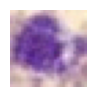

In [40]:
data = np.load('DDIM_10000_1.npz')
images = data['images']
print(images.shape)
plt.figure(figsize=(1, 1))
plt.axis('off')
plt.imshow(np.transpose(images[10], (1, 2, 0)))
plt.show()

## Compute FID

In [41]:
transforms = v2.Compose([
    v2.ToDtype(torch.float32, scale=True),
    v2.Resize((299, 299)),
    v2.Normalize(mean=[0.485, 0.456, 0.406],
                 std=[0.229, 0.224, 0.225]),
    v2.Lambda(lambda x: (x - x.min()) / (x.max() - x.min()))  # [0, 1]
])

In [42]:
def compute_activations(images: torch.Tensor | ConcatDataset, model: InceptionV3, 
                        batch_size=512, save_path='activations.npz'):
    ''' Computes Inception-v3's activations for all images. '''
    data_loader = DataLoader(images, batch_size=batch_size, shuffle=False)
    output = []
    model.to(device)
    
    with torch.inference_mode():
        for X in tqdm(data_loader, desc=f"Retrieving activations", colour="#00ff00"):
            if type(X) == list:  # Real image dataloaders contain labels
                X, _ = X
                
            X.to(device)
            X = transforms(X)
            activations = model(X)[0]
            
            output.append(activations.cpu().numpy())
    
    output = np.concatenate(output, axis=0)   
    np.savez_compressed(save_path, activations=output)
    print(f"Saved {len(images)} activations to {save_path}")

In [55]:
def compute_FID(real_activations: np.ndarray, fake_activations: np.ndarray):
    ''' Compute FID score based on given image activations from Inception-v3 '''
    # Get extracted features to numpy array
    real_activations = real_activations.squeeze()
    fake_activations = fake_activations.squeeze()
    
    # Compute mean and covariance of the features
    real_mean, real_cov = np.mean(real_activations, axis=0), np.cov(real_activations, rowvar=False)
    fake_mean, fake_cov = np.mean(fake_activations, axis=0), np.cov(fake_activations, rowvar=False)
    
    # Compute Frechet Distance of Inception's features (FID)
    fid = calculate_frechet_distance(real_mean, real_cov, fake_mean, fake_cov)
    
    return fid

In [44]:
# pytorch_fid's InceptionV3 model (pretrained on ImageNET)
dims = 2048
block_idx = InceptionV3.BLOCK_INDEX_BY_DIM[dims]
inception_model = InceptionV3([block_idx]).to(device)

In [45]:
for dataset in ['VAE', 'GAN']:
    if not os.path.isfile(f'{dataset}_RealA.npz'):
        images = vae_full_dataset if dataset == 'VAE' else gan_full_dataset
        compute_activations(images, inception_model, batch_size=512, save_path=f'{dataset}_RealA.npz')
    else:
        print(f'{dataset}_RealA.npz already exists!')

VAE_RealA.npz already exists!
GAN_RealA.npz already exists!


In [46]:
for model in ['VAE', 'GAN', 'DDIM']:
    for i in range(5):
        if not os.path.isfile(f'{model}_10000_{i+1}A.npz'):
            data = np.load(f'{model}_10000_{i+1}.npz')
            images = torch.tensor(data['images'])
            compute_activations(images, inception_model, batch_size=512, save_path=f'{model}_10000_{i+1}A.npz')
        else:
            print(f'{model}_10000_{i+1}A.npz')

VAE_10000_1A.npz
VAE_10000_2A.npz
VAE_10000_3A.npz
VAE_10000_4A.npz
VAE_10000_5A.npz
GAN_10000_1A.npz
GAN_10000_2A.npz
GAN_10000_3A.npz
GAN_10000_4A.npz
GAN_10000_5A.npz
DDIM_10000_1A.npz


Retrieving activations: 100%|██████████| 20/20 [07:22<00:00, 22.13s/it]


Saved 10000 activations to DDIM_10000_2A.npz


Retrieving activations: 100%|██████████| 20/20 [07:17<00:00, 21.88s/it]


Saved 10000 activations to DDIM_10000_3A.npz


Retrieving activations: 100%|██████████| 20/20 [07:43<00:00, 23.19s/it]


Saved 10000 activations to DDIM_10000_4A.npz


Retrieving activations: 100%|██████████| 20/20 [07:38<00:00, 22.90s/it]


Saved 10000 activations to DDIM_10000_5A.npz


In [57]:
FID_scores = {}
RUNS = 5  # Random samplings on the real datasets

for run in tqdm(range(RUNS), desc='Computing FID scores', colour="#00ff00"):
    idxs = random.sample(range(len(vae_full_dataset)), 10000)
    FID_scores[run] = {}
    for model in ['VAE', 'GAN', 'DDIM']:
        # Retrieve sampled real dataset image activations
        real_activations = np.load(f'{'VAE' if model=='VAE' else 'GAN'}_RealA.npz')['activations']
        real_activations = real_activations[idxs]
        
        # Retrieve generated image ativations for model and run
        fake_activations = np.load(f'{model}_10000_{run+1}A.npz')['activations']
        
        fid = compute_FID(real_activations, fake_activations)
        FID_scores[run][model] = fid

pprint(FID_scores)

Computing FID scores: 100%|██████████| 5/5 [00:59<00:00, 11.94s/it]

{0: {'DDIM': np.float64(5.9673793405666515),
     'GAN': np.float64(14.72423706722276),
     'VAE': np.float64(12.656063791776006)},
 1: {'DDIM': np.float64(6.003733523214521),
     'GAN': np.float64(14.662035900520607),
     'VAE': np.float64(12.675222266573172)},
 2: {'DDIM': np.float64(5.93088188591031),
     'GAN': np.float64(14.671135013644573),
     'VAE': np.float64(12.412696301437137)},
 3: {'DDIM': np.float64(5.9261556865158695),
     'GAN': np.float64(14.621940147997407),
     'VAE': np.float64(12.514884247131846)},
 4: {'DDIM': np.float64(5.9207984038062875),
     'GAN': np.float64(14.535875315867713),
     'VAE': np.float64(12.494714210443192)}}


In [62]:
vae_scores = np.array([FID_scores[run]['VAE'] for run in range(RUNS)])
gan_scores = np.array([FID_scores[run]['GAN'] for run in range(RUNS)])
ddim_scores = np.array([FID_scores[run]['DDIM'] for run in range(RUNS)])

print(f'VAE | Mean: {np.mean(vae_scores):.3f}  Std: {np.std(vae_scores):.3f}')
print(f'GAN | Mean: {np.mean(gan_scores):.3f}  Std: {np.std(gan_scores):.3f}')
print(f'DDIM | Mean: {np.mean(ddim_scores):.3f}  Std: {np.std(ddim_scores):.3f}')

VAE | Mean: 12.551  Std: 0.100
GAN | Mean: 14.643  Std: 0.063
DDIM | Mean: 5.950  Std: 0.032


# Extra visualizations

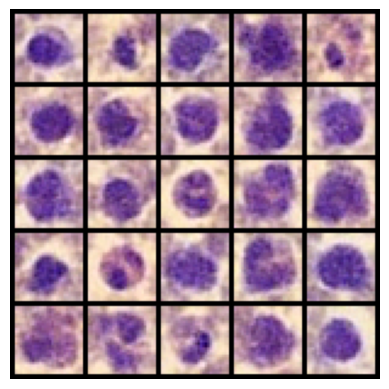

In [36]:
imgs = ddim_sample(ddpm, n_steps=25, n_samples=25, eta=0.1)
imgs_norm = ((imgs + 1) / 2).clamp(0, 1)
grid = make_grid(imgs_norm, nrow=5)
plt.imshow(to_pil_image(grid))
plt.axis('off')
plt.show()

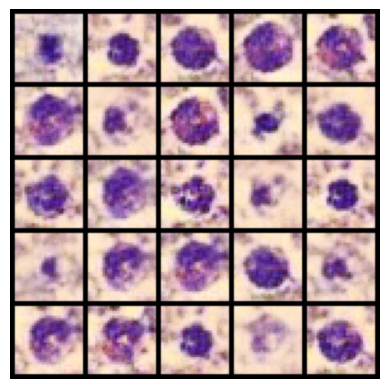

In [37]:
z = torch.randn(25, GAN_ZDIM)
with torch.inference_mode():
    imgs = netG(z)
imgs_norm = ((imgs + 1) / 2).clamp(0, 1)
grid = make_grid(imgs_norm, nrow=5)
plt.imshow(to_pil_image(grid))
plt.axis('off')
plt.show()

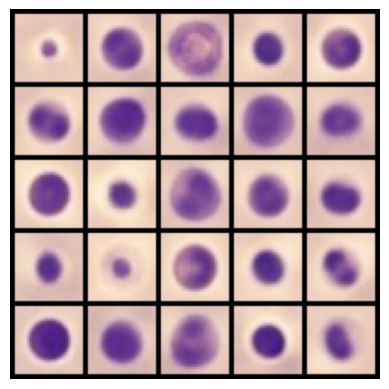

In [39]:
z = torch.randn(25, GAN_ZDIM)
with torch.inference_mode():
    imgs = vae.decode(z)
grid = make_grid(imgs, nrow=5)
plt.imshow(to_pil_image(grid))
plt.axis('off')
plt.show()

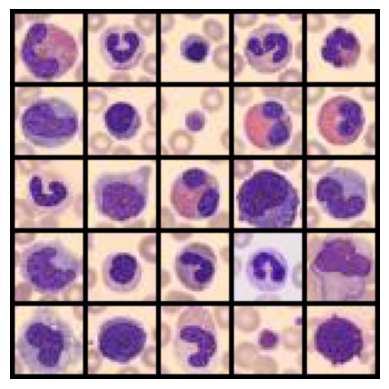

In [44]:
imgs = next(iter(vae_loader))[0][:25]
grid = make_grid(imgs, nrow=5)
plt.imshow(to_pil_image(grid))
plt.axis('off')
plt.show()